<a href="https://colab.research.google.com/github/zune2/colab-notebooks/blob/main/2026-10-24-EP010-news-cagegory-selector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install --upgrade torchao peft transformers

In [4]:
# ==============================================================================
# Cell 1: Total Unified Custom Jev Variant Pipeline (ModernBERT + LoRA - Fixed)
# ==============================================================================

import os
import json
import torch
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from peft import LoraConfig, get_peft_model, TaskType

# ------------------------------------------------------------------------------
# 1. Synthetic Dataset Definition (Jev/Laya [State, Question, Target] Structure)
# categories = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
# ------------------------------------------------------------------------------
# ==============================================================================
# 데이터 밸런싱을 거친 최종 고품질 합성 데이터셋 (기존 배열과 교체하세요)
# ==============================================================================
# ==============================================================================
# 모든 카테고리를 정확히 5건씩 매핑한 완전 균등(Balanced) 합성 데이터셋
# ==============================================================================
synthetic_dataset = [
  {"state": "대통령실, \"국정운영 동력 확보 주력... 경제 살리기 총력\" 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '총선 승리' 위한 전략 마련 분주... 공천 경쟁 가열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 여당 비대위원장 전격 사퇴... 정계 '충격파'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회, '민생법안' 처리 두고 진통... 여야 대치 장기화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정부, '연금 개혁안' 초읽기... 국민 공청회 개최 예정", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당 대표, \"정권 심판론 확산... 민심 이반 가속화\" 경고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 여당 중진, 내년 총선 불출마 선언... 배경 '촉각'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, \"한미일 안보 협력 강화... 북핵 위협 공동 대응\" 천명", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "법사위, '검수완박' 재논의 착수... 여야 격렬 공방 예상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "지방선거 후보 등록 마감... 예측불가 '빅매치' 속출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령 지지율, '긍정' 하락세... 부정 평가 50% 육박", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '특별감찰관' 임명 두고 신경전... 장기 표류 조짐", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[브리핑] 국방부, \"DMZ 일대 북한군 동향 예의주시\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "교육부, '늘봄학교' 전국 확대 방안 발표... 현장 혼란 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '저출산 문제' 해법 모색... 특위 구성 논의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국무총리, \"민생 안정 최우선... 물가 잡기에 총력\" 약속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '대통령 거부권' 행사 비판... \"독단적 국정 운영\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 尹 대통령, 해외 순방 마치고 귀국... 주요 성과 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당 혁신위, '세대교체' 추진... 험지 출마 요구 파장", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "시민사회, '정치 개혁' 촉구 집회... \"특권 내려놔야\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 예산안 심사, '삭감' 요구 빗발... 진통 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "북한, \"대미 강경책 유지... 핵무력 강화 지속\" 주장", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "법무부, '사법 개혁' 방향 제시... 검찰 독립성 강화 초점", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 차기 당대표 주자, '정책 경쟁' 본격화... 비전 제시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "총선 D-day 1년, 여야 '승부수' 띄우기 시작", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"야당 협치 제안... 열린 자세로 논의\" 표명", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회, '청문회' 파행... 증인 출석 놓고 여야 공방", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 대법원, '정치자금법 위반' 국회의원 유죄 확정", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '중도층' 표심 잡기 총력... 정책 간담회 개최", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '민생 추경' 편성 요구... \"경제 위기 극복 시급\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외통위, '대일 관계 개선' 논의... 역사 문제 접근법 고심", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 차관급 인사 단행... '전문성' 강화 초점", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국정감사, '정책 실패' 도마 위... 책임 공방 가열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령, \"국민 통합 위해 노력... 갈등 해소 방안 찾을 것\" 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '선거제 개편' 놓고 입장차... 합의 난항 예상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 북한, 동해상으로 미사일 발사... 한반도 긴장 고조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 본회의, '쟁점 법안' 표결... 밤샘 토론 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "통일부, '남북 관계 개선' 방안 모색... 대화 재개 제안", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[여론조사] 차기 대선 주자, '○○○' 지지율 상승세", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "시민단체, '정치 혐오' 해소 촉구... \"건강한 토론 필요\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '보수 혁신' 기치... 인적 쇄신 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '진보 가치' 수호 강조... 서민 경제 정책 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령, '비상경제 민생회의' 주재... 물가 안정 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 국방위, '국방백서' 논의... 북한 위협 평가 쟁점", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 장관 후보자, '인사청문회' 통과... 취임 임박", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '방송법 개정안' 두고 격돌... 미디어 장악 논란", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, \"G7 정상회의 성공적 개최... 글로벌 리더십 강화\" 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 검찰, '정치인 비리 의혹' 수사 본격화... 압수수색", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 정개특위, '선거구 획정' 논의... 갈등 심화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"국민과의 소통 강화... 열린 청와대 표방\" 선언", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '청년 정치인' 발굴 총력... 정치 신인 육성", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '소상공인 지원' 공약 발표... 민생 경제 살리기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 국회, '탄핵소추안' 발의... 정국 요동", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '총선 승리' 위한 '세불리기' 경쟁 치열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '가짜뉴스' 규제 법안 두고 대립... 표현의 자유 논란", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "통일부, '북한 이탈 주민' 정착 지원 강화 방안 마련", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 당대표, '계파 갈등' 봉합 시도... 리더십 시험대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 과방위, '인공지능 규제' 법안 논의... 산업 진흥 vs 윤리", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령, '취임 2주년' 기자회견... 국정 운영 방향 제시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '개헌' 논의 불 지펴... 총선 쟁점 부상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '대정부 질문' 통해 '정책 실패' 맹공", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 북한, 서해상 포격 훈련... 긴장 수위 최고조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, \"미중 갈등 속 '전략적 균형 외교' 추진\" 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[여론조사] 차기 총선, '정권 심판론' vs '안정론' 팽팽", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 문체위, '공영방송 지배구조' 개선 논의... 여야 입장차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"경제 성장률 전망치 하향 조정... 위기 극복 총력\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '혁신 공천' 시사... 현역 의원 물갈이 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '정부 견제' 총력... 국회 상임위 보이콧 시사", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 전직 장관, '총선 출마' 선언... 정치 복귀 신호탄", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 보건복지위, '의료 개혁' 법안 심사... 논의 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '지방 소멸' 해법 모색... 지역 균형 발전 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '당정대' 협의체 가동... 정책 조율 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '장외 투쟁' 돌입... 정부 실정 규탄", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 대통령, '국정 지지율' 최저치 경신... 국정 동력 약화 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, \"중국과 '전략적 협력 동반자' 관계 발전 노력\" 표명", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[여론조사] 국회 신뢰도 '하락'... 불신 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 환노위, '노동 개혁' 법안 공방... 노사정 합의 난항", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"북한 도발에 '단호한 대응'... 억지력 강화\" 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '민생 토론회' 개최... 현장 의견 수렴 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '특검 도입' 촉구... '○○ 의혹' 진실 규명 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 법무부 장관, '검찰 인사' 단행... 조직 안정화 총력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 교육위, '고교 학점제' 도입 논의... 교육 현장 변화 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '탄소 중립' 정책 경쟁... 미래 먹거리 창출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '청년층 표심' 잡기 총력... 주거 지원 확대 공약", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '부자 감세 철회' 주장... 서민 부담 완화 촉구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 대법원, '위헌 법률 심판' 제청... 파장 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 행안위, '경찰 개혁' 법안 심사... 권한 분산 쟁점", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령, '신년 기자회견' 개최... 2024 국정 운영 비전 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '중대 재해처벌법' 개정 추진... 기업 부담 완화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '국민 연금 개혁' 공약... 노후 소득 보장 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, \"인도-태평양 전략 추진... 지역 안정 기여\" 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 국정원, '북한 해킹' 경고... 사이버 안보 강화 촉구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 정보위, '국정원 개혁' 논의... 정치 중립성 확보 방안", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"미국과의 '반도체 동맹' 강화... 공급망 안정화\" 역설", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '가계 부채' 해법 모색... 경제 위기 대응 총력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 국방부, '독자 핵 개발' 주장 일축... 한반도 비핵화 원칙 고수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 산자위, '원전 정책' 논의... 에너지 전환 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '인구 절벽' 심각성 인식... 특단의 대책 촉구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '경제 민주화' 강조... 대기업 규제 강화 시사", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '검찰 독재' 비판... 권력기관 개혁 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정부, '부동산 정책' 전면 재검토 착수... 시장 안정화 총력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야 원내대표, '영수회담' 성사 여부 촉각... 정국 돌파구 모색", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 북한, '전원회의' 개최... 대남·대미 전략 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회, '국민동의청원' 제도 활성화... 민의 반영 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령, '지역 균형 발전' 강조... 지방 시대 개막 선언", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '차기 총선 필승' 다짐... 조직 정비 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '대정부 투쟁' 수위 높여... 장관 해임 건의안 발의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[단독] 정치권, '총선 불출마' 선언 잇따라... 세대교체 바람", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "외교부, '우크라이나 재건' 참여 발표... 국제사회 기여 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 운영위, '대통령실 인사' 검증 착수... 공정성 논란", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여야, '이태원 참사' 특별법 제정 합의... 진실 규명 총력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "대통령실, \"국민 부담 경감 위한 세제 개편 검토\" 시사", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "정치권, '지구 온난화' 대응 촉구... 탄소 중립 사회 전환", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "[속보] 법무부 장관, 국회 불출석... 여야 격렬 대치", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "국회 상임위, '청년 일자리' 창출 방안 논의... 해법 모색", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "여당, '민생 현안' 해결 주력... 현장 방문 이어져", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "야당, '정부 무능' 비판... 경제 정책 전면 수정 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
  {"state": "한은, 기준금리 동결 '만장일치'…시장 예측 적중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "원/달러 환율 1350원 '재돌파'…수출 기업 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "코스피 2700선 '돌파'…외국인 순매수 지속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "속보: Fed 추가 금리 인상 '시사'…글로벌 증시 촉각", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "반도체株 '불기둥'…HBM 수요 폭발에 기대감 증폭", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'역전세' 주의보 확산…정부, 긴급 대책 마련 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "소비자물가 상승률 3%대 '턱걸이'…체감 물가는 여전히 고공행진", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "삼성전자, 'AI 반도체 초격차 유지' 선언…투자 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "유가 급등 '비상'…중동 불안에 에너지 안보 위협", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "中 경제 회복 둔화 '그림자'…韓 수출 영향 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "K-배터리, 美 IRA '수혜' 전망…증설 경쟁 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'영끌족 비상' 서울 아파트값 하락세 멈추나?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "전세사기 피해자 속출…국회, 특별법 재논의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "ESG 경영 '필수'…기업들, 친환경 전환에 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "금감원, '불법 공매도' 철퇴 예고…시장 건전성 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "비트코인 4천만원대 '재진입'…가상자산 시장 '들썩'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "청년 실업률 5%대 '고착화'…정부, 고용 대책 고심", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "한국 조선업, 고부가 LNG선 '수주 낭보'…중국 추격 따돌려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "신기술 스타트업 '자금난' 심화…투자 빙하기 지속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'고금리' 장기화 우려…가계부채 '뇌관' 터지나", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "증권사, 하반기 증시 '상저하고' 전망…변동성 유의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "포스코, 친환경 철강 전환 가속…'수소환원제철' 로드맵 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "농산물 가격 '들썩'…폭염·태풍 여파에 공급 불안정", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "온라인 플랫폼 '수수료' 논란…소상공인 부담 가중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "전기차 보조금 축소 '시사'…자동차 업계 희비 교차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "IMF, '韓 경제 성장률 하향 조정' 경고…글로벌 불확실성 증대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "주택담보대출 금리 '꿈틀'…DSR 규제 완화 여부 촉각", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "대형마트 '폐점' 잇따라…온라인 쇼핑 전환 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "반도체 수출 '바닥' 찍었나?…회복 기대감 '솔솔'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "공공요금 인상 압박 '고조'…서민 경제 '이중고'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "FOMC 의사록 공개 '초미의 관심'…금리 인상 신호 찾나", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'김치 프리미엄' 다시 등장…가상자산 시장 과열 경고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "대기업 투자 '주춤'…경기 침체 장기화 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "글로벌 반도체 장비 기업, 韓 투자 확대…'K-칩스' 초석 다지기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "국토부, '전세사기' 근절 위한 추가 대책 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "고령화 시대 '연금 개혁' 시급…국민연금 재정 고갈 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "엔저 장기화 '빨간불'…日 수출 경쟁력 강화에 韓 기업 영향은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "은행권, '횡재세' 도입 논란…사회적 책임론 대두", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "자영업자 폐업 '속출'…고금리·고물가 이중고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "부동산 PF 대출 '부실' 우려…금융당국, 리스크 관리 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "제약바이오 업계, R&D 투자 확대…신약 개발 '총력전'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'슈퍼 엔저' 시대…일본 여행객 증가에 면세점 특수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "정부, '수출 활력' 회복 총력…무역수지 개선 기대감", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "증시 전문가들, '하반기 IT·전기차 '주목''", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'재건축' 규제 완화 기대감…서울 주요 단지 '들썩'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "석유화학 업계 '비상'…중국발 공급 과잉에 실적 악화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "식료품 물가 '고삐 풀렸다'…라면·과자 줄줄이 인상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "고용 시장 '이중적'…제조업 침체 vs 서비스업 회복", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "글로벌 인플레이션 '재점화' 우려…에너지 가격 변동성 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "저출산 고령화 '경제 성장률 발목'…생산성 저하 심각", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "한전, '적자' 누적에 전기요금 추가 인상 불가피?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "KDI, '韓 경제 내년 2%대 성장 전망'…불확실성 여전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "자사주 매입·소각 '활발'…주주 환원 정책 강화 움직임", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'배터리 전쟁' 가열…전고체 배터리 상용화 경쟁 치열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "철강업계, 친환경 생산 전환 '고민'…탄소 배출권 비용 부담", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "온라인 명품 시장 '급성장'…MZ세대 큰손으로 부상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "외식 물가 '끝 모르는' 상승…점심 값 1만원 시대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "반도체 감산 '효과' 있나?…재고 소진 여부에 관심 집중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "신용카드 연체율 '상승'…서민 금융 취약성 증대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "건설 경기 '먹구름'…미분양 주택 증가세 심상찮다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "바이오시밀러, 글로벌 시장 '강타'…K-바이오 위상 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "유통업계, '배송 경쟁' 심화…퀵커머스 시장 뜨겁다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'디지털세' 도입 논의 재점화…글로벌 IT 기업 영향은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "정부, '초거대 AI' 산업 육성…미래 성장 동력 확보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "원자재 가격 '요동'…글로벌 공급망 불안정 지속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "가계 대출 총량 규제 '강화'…총부채원리금상환비율(DSR) 한도 축소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'메타버스' 투자 열기 '식나'…시장 재편 움직임", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "저축은행 '건전성' 악화 우려…부동산 PF 부실 영향", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "수출입 물가 '반등'…환율 상승·유가 인상 영향", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'금리 인하' 기대감 '솔솔'…연준 피봇 시점은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "로봇 산업 '급성장'…생산성 혁신 견인차 역할 기대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "글로벌 경기 둔화 '현실화'…한국 경제 '버팀목' 수출 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'상속세' 완화 논의 재점화…기업 투자 활성화 기대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "제4이통사 '출범' 논의…통신 시장 경쟁 촉발될까", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'초전도체' 테마주 '급등락'…과열 경고 속 투자 주의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "신재생에너지 발전 비중 확대…ESS 시장 '주목'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "해외 주식 투자 '열풍'…서학개미 순매수 상위 종목은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'최저임금' 인상 논의 시작…노사 양측 팽팽한 신경전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "정부, '소상공인' 대출 만기 연장…자금난 해소 지원", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "국채 금리 '급등'…재정 건전성 우려에 투자 심리 위축", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'택시비' 인상 도미노…대중교통 요금 줄줄이 인상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'중국 봉쇄' 해제 효과 미미…내수 회복 더딘 이유", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "반도체 업황 '턴어라운드' 예상…수출 반등 기대감", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'수출 효자' 자동차, 친환경차 전환 가속…글로벌 경쟁 심화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'로봇세' 도입 논의…자동화 시대의 새로운 세금 이슈", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'골드러시' 재개?…안전자산 금값 '고공행진'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "P2P 투자 플랫폼 '규제' 강화…투자자 보호 '강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "금융지주, 비은행 부문 '강화'…사업 포트폴리오 다각화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'탄소중립' 달성 위한 녹색 채권 발행 '활발'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "글로벌 경기 침체 속 'K-푸드' 수출 효자 등극", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'소비 양극화' 심화…고가품 vs 초저가품 대비 매출 증대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'인구 절벽' 심화…장기적 경제 성장 잠재력 '하락'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "증시 변동성 '확대'…개인 투자자 '옥석 가리기' 중요", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'환율 방어' 위한 외환 당국 '고군분투'…시장 개입 지속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'블루 아카이브' 등 K-게임, 해외 시장 '돌풍'…수출 효자 역할", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'대환 대출' 플랫폼 출시…고금리 부담 경감 기대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "정부, '규제 샌드박스' 확대…신산업 육성 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'기업 밸류업' 프로그램 도입…저평가 기업 가치 제고 노력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'우주 경제' 시대 개막…민간 투자 활성화 전망", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "'플랫폼 노동' 확산…고용 안정성 확보 위한 논의 본격화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
  {"state": "경찰, '이태원 압사 사고' 특별수사본부 가동...책임 소재 규명 총력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: '전세 사기' 피해자 극단 선택 시도...사회적 파장 일파만파", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "요양병원 간병인 학대 논란, 인권위 '실태 조사' 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "서울시, '밤샘 주차' 민원 폭증에 단속 강화 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "초등생 학교폭력, '촉법소년' 제도 개선 목소리 고조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "속보: 영등포역 인근 지하철 탈선...출근길 대혼란, 인명 피해 확인 중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "아파트 층간소음 분쟁, 결국 살인으로...사회적 공론화 필요성 대두", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "檢, '보이스피싱' 조직원 50명 무더기 기소...피해액 수백억", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "어린이집 아동학대 CCTV 영상 공개...부모들 '분노' 폭발", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "긴급: 수도권 대규모 정전 사태...수십만 가구 피해, 복구 작업 중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "고령화 사회 '그림자 살인' 급증...돌봄 시스템 붕괴 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "MZ세대 '번아웃 증후군' 심각...직장 문화 개선 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "배달 플랫폼 노동자 '과로사' 속출...안전망 구축 촉구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가짜뉴스 '가짜 신분증' 판매 기승...청소년 범죄 악용 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "미세먼지 '최악' 수준...외출 자제령, 시민 건강 적신호", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "서울대병원, '간호사 태움' 문화 고발...병원 측 '진상 규명'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "장애인 이동권 시위 장기화...정부 '사회적 합의' 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 유명 연예인 마약 투약 혐의...경찰 내사 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "무더위 쉼터 '부족' 지적...노인 취약 계층 안전 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "재개발 지역 '젠트리피케이션' 논란...원주민 이주 대책 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "코로나19 재확산 조짐...방역 당국 '경각심' 당부", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "지하철역 스크린도어 사망 사고...안전 불감증 또 도마 위", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "청소년 도박 문제 심각...온라인 불법 사이트 '무방비 노출'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 공무원 '갑질 논란' 내부 고발...시민단체 공동 대응", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "산부인과 '소아과 오픈런' 대란...저출산 시대 의료 시스템 붕괴 위기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "대기업 직장 내 괴롭힘 '은폐 의혹'...고용노동부 특별 근로감독", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "노인 빈곤율 OECD 최고...사회 안전망 확충 '절실'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "AI 챗봇 윤리 논란 '인종차별' 발언...개발사 사과문 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "불법 공유 오피스 '사기' 주의보...청년 창업가 피해 속출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "아동 성범죄자 '전자발찌 훼손' 도주...시민들 불안감 고조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "속보: 서울 외곽순환도로 대형 추돌사고...교통 마비, 인명 피해 발생", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가상화폐 투자 사기 '조직적 범죄' 밝혀져...수천 명 피해", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "쓰레기 무단 투기 '골치'...지자체 '양심 스티커' 도입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "주거 취약계층 '쪽방촌' 화재...겨울철 화재 예방 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "교권 추락 '심각' 수준...교사들 '생존권' 사수 집회", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "청년 자살률 증가세...정부 '정신 건강 지원' 강화 방안 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "펫샵 '강아지 공장' 실태 고발...동물 학대 논란 확산", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "보육교사 처우 개선 '요구'...보육 현장 인력난 심화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "수돗물 유충 발견 '충격'...시민들 '불안감' 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "독거노인 고독사 급증...사회적 관심과 지원 '시급'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가정 폭력 피해 아동 '쉼터 부족' 문제...보호 시스템 허점 노출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 유명 유튜버 '뒷광고' 논란...공정위 조사 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "전국 고교생 '수능 포기' 급증...학벌주의 사회의 그늘", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "산업 현장 '중대 재해' 끊이지 않아...기업 '안전 투자' 소홀 지적", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "온라인 커뮤니티 '혐오 표현' 범람...사회적 갈등 증폭 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "빈집털이범 '상습범' 검거...설 연휴 빈집털이 주의보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "수도권 대기질 '빨간불'...노후 경유차 운행 제한 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "성형외과 '불법 광고' 기승...환자 안전 위협 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "결식아동 급증...지자체 '긴급 푸드뱅크' 확대 운영", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "불법 도박 사이트 '청소년 유인' 심각...학부모들 '분노'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "택시 승차 거부 '여전'...시민들 '불편' 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "유명 백화점 '명품 짝퉁' 판매 적발...소비자 신뢰도 하락", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "장마철 침수 피해 속출...지자체 '재난 대비' 미흡 지적", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "공항철도 '좌석 부족' 논란...출퇴근 시민들 '불만 폭발'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가정폭력 피해 여성 '쉼터 부족'...피해자 이중 고통", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "온라인 게임 '사행성' 논란...청소년 중독 문제 대두", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "사회복지사 '번아웃' 심각...열악한 처우 개선 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "도로 위 '보복 운전' 극성...블랙박스 제보 '활발'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "고시원 화재 '인명 피해'...열악한 주거 환경 개선 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "취업 사기 '위장 취업' 수법 진화...청년들 '피눈물'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "불법 촬영물 '유포' 기승...디지털 성범죄 '뿌리 뽑아야'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "지하철 노숙인 '급증'...사회적 관심과 지원 '절실'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 대기업 임원 '횡령 혐의' 내부 고발...검찰 수사 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "유명 프랜차이즈 '갑질 논란' 재점화...불매운동 확산", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "폭염 속 '온열 질환' 비상...농촌 노인들 '무방비 노출'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "대학생 '등록금 인상' 반대 시위...학비 부담 '가중'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "인터넷 중독 '청소년 뇌' 변화...정부 '치유 프로그램' 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "쓰레기 소각장 '악취 민원' 끊이지 않아...주민들 '고통' 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "음주운전 '상습범' 면허 취소해도 또...재범 방지 대책 '시급'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "무인점포 '절도' 급증...CCTV 사각지대 '보안 강화' 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "반려동물 '유기' 심각...동물 등록제 '실효성' 논란", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "노인 일자리 '질' 문제...단순 노무직 치중 '개선 필요'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "아파트 경비원 '부당 해고' 논란...노동위 '구제 신청' 접수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "소방관 '외상 후 스트레스' 심각...정신 건강 지원 '강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "길거리 '묻지마 범죄' 불안감 확산...경찰 '순찰 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "출산휴가 '눈치 보기'...여성 경력 단절 '심각'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "학교 급식 '이물질' 발견...학부모들 '불안감' 증폭", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "수련원 '수학여행' 도중 사고...학생 2명 부상, 안전 관리 허점", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "대리 수술 '환자 사망' 논란...의료계 '불법 행위' 근절 촉구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 고위 공직자 '부동산 투기' 의혹...시민단체 고발", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "사설 어린이집 '꼼수 폐원'...학부모들 '발 동동'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "해변가 '불법 야영' 기승...환경 오염 및 안전 문제 대두", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "불법 주정차 단속 '강화'...과태료 인상, 시민들 '불만'도", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "청년 신용불량자 '급증'...빚 갚지 못해 '좌절'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "요양원 '코로나 집단 감염'...감염병 취약 시설 '비상'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "쓰레기 매립장 '포화 상태'...대체 부지 확보 '난항'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "음식점 '원산지 속이기' 단속...소비자들 '불신' 가중", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "정신병원 '강제 입원' 논란...인권 침해 우려 확산", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "속보: 도심 대형 싱크홀 발생...통제, 시민 불편 초래", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "고속도로 '로드킬' 급증...동물 보호 및 운전자 안전 위협", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "불법 스포츠 토토 '청소년 범죄' 연결...경찰 '강력 단속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "층간 소음 '방치' 이웃 갈등...지자체 '조정 중재' 나선다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "콜센터 직원 '감정 노동' 고충...인권 보호 대책 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "농촌 마을 '빈집' 속출...고령화와 인구 감소의 그림자", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가짜 약 '온라인 판매' 기승...국민 건강 '빨간불'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "청년 전월세 대출 사기 '주의보'...피해자 '막막'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "학교 급식실 '냉난방 부실'...조리원들 '고통' 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "단독: 재벌가 3세 '운전기사 갑질' 폭로...사회적 공분", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "지하철역 '에스컬레이터' 고장 잦아...시민 안전 '위협'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "아파트 단지 '집단 민원' 폭발...관리사무소 '난감'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "무속인 '사기 행각' 극성...사회적 약자 '표적'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "택배 기사 '과로사' 끊이지 않아...근로 환경 개선 '촉구'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "보육원 아동 '시설 퇴소' 후 자립 어려움...사회적 지원 '부족'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "전국 초중고 '학생 수 감소' 심화...학교 통폐합 '가속화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "어린이 보호구역 '안전' 비상...음주운전 처벌 강화 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "구직 포기 청년 '니트족' 급증...사회적 고립 '우려'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "지역 축제 '바가지요금' 논란...관광객들 '불만 폭주'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "도로변 '쓰레기 불법 소각' 적발...미세먼지 유발, 환경 오염", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "가습기 살균제 피해 '10년' 넘도록...피해자들 '고통' 여전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "음식물 쓰레기 '처리 대란' 우려...수거 거부 사태 발생", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
  {"state": "MZ세대 '인생샷' 성지! 요즘 뜨는 서울 팝업 스토어 TOP 5", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "슬기로운 '집콕' 생활? 홈베이킹&DIY 키트 인기 폭발!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "해외여행 대신 '호캉스' 대세! 특급호텔 이색 패키지 '눈길'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'디지털 디톡스' 시대, 멍 때리기 챌린지 왜 떴을까?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "친환경 소비 '필수템' 등극! 에코백 넘어 '제로웨이스트' 라이프", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "[단독] '혼술족' 급증! 프리미엄 막걸리&수제 맥주 시장 '활활'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려동물과 함께하는 삶, '펫팸족' 위한 필수 여행지 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "K-컬처의 힘! 한국 웹툰, 전 세계 'OTT' 타고 돌풍 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'워라밸' 시대의 미니멀 라이프, 비울수록 행복한 이유", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "봄맞이 '플랜테리어' 도전? 식물 초보도 쉬운 인테리어 팁", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "요즘 대세 '힙지로' 감성 카페 투어, 숨겨진 보석같은 공간들", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "간편한 '밀키트' 요리, 이젠 집에서 미슐랭 뺨치는 맛을!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "나만의 '향기'를 찾아서... 니치 향수 & 퍼퓸 클래스 '북적'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "코로나19 이후 '언택트' 캠핑족 급증! 차박 명소 어디?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "스트레스 해소엔 'ASMR'이 최고? 숙면 유도 사운드테라피 효과", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "2023 뷰티 트렌드 '클린 뷰티', 착한 성분으로 피부 건강까지!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'가심비' 추구하는 MZ세대, '작은 사치' 디저트 열풍", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "지친 일상 '힐링' 프로젝트! 템플스테이 & 숲속 명상 체험기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "패션계 '뉴트로' 열풍! Y2K 감성 아이템 다시 뜬다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "내 손으로 만드는 '홈카페' 레시피, 바리스타 부럽지 않네!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "퇴근 후 '나만의 시간', OTT로 즐기는 숨겨진 명작 발견!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "육아는 장비빨? 스마트 육아템으로 '육퇴' 시간 벌어요!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "환경 생각하는 '비건 라이프', 맛과 건강 두 마리 토끼 잡기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "서울 근교 '감성 숙소' BEST 5! 복잡한 도시 벗어나 '쉼' 찾기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'폰트 맛집'으로 변신한 브랜드들, 개성 담은 서체 디자인 '주목'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '인생네컷' 열풍, 추억 담는 '인생샷' 명당 어디?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "몸과 마음을 다스리는 '요가 & 필라테스', 집에서도 가능!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려식물 '엄빠'들 모여라! 식물 덕후 위한 이색 카페 '화제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "슬기로운 '중고거래' 팁! 패션 아이템부터 가전까지 '알뜰 쇼핑'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'K-드라마' 속 패션 아이템 완판 행진! 글로벌 인기 실감", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집에서 즐기는 '오마카세' 스타일? 고급 식재료로 미식 경험", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "당신의 '퍼스널 컬러'는? 뷰티 컨설팅으로 나만의 매력 찾기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "버킷리스트 실현! '혼자 떠나는 여행' 족 위한 꿀팁 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "음악으로 위로받는 시대, '플레이리스트'로 하루를 위로해요", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'편의점 핫템' 속보! 간편식 넘어 디저트까지 MZ세대 사로잡다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "내 아이와 함께 '친환경' 체험! 에코 교육 프로그램 인기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "똑똑한 '스마트홈' 시대, AI 스피커로 우리 집이 달라졌어요!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "주말엔 '산책'이 최고! 서울 도심 속 숨겨진 힐링로드 TOP 3", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'셀프 인테리어' 열풍! 전문가 부럽지 않은 가성비 팁 대방출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "소확행을 넘어 '확행' 시대! 작은 것에서 큰 행복 찾기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "취미로 즐기는 '독서 모임', 지적 교류와 사회생활 두 마리 토끼", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "지속가능한 'ESG' 라이프! 착한 기업 제품으로 윤리적 소비", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '골프 입문' 열풍, 패션부터 용품까지 '인싸템' 주목", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "우리 아이 '오감 발달' 미술 놀이, 집에서 쉽게 즐기는 방법", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집에서 즐기는 '미식' 경험, 와인 페어링 & 치즈 플레이트 팁", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "트렌디한 '젠더리스' 패션, 경계를 허무는 새로운 스타일 제안", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "힐링 핫플 '연트럴파크', 주말 나들이 명소로 '인산인해'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "K-팝 스타들의 '일상템' 따라잡기, 팬심 저격 아이템 인기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "새로운 '여행 트렌드' 등장! 살아보는 여행 '한 달 살기' 인기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'수면의 질'이 곧 건강! 숙면 유도 아이템 & 루틴 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'멍냥이'를 위한 프리미엄 사료 전쟁! 펫푸드 시장 '후끈'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "힙스터들의 성지 '성수동', 감성 카페와 쇼룸 투어 필독 코스", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "OTT 플랫폼 '콘텐츠 전쟁', 드라마 넘어 예능·다큐까지 '풍성'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "나만의 '홈짐' 만들기, 집에서도 완벽한 홈트레이닝 가능!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '줄서는 맛집' 리스트! 웨이팅도 즐거운 미식 탐험", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "향기로 공간을 채우다! 디퓨저, 룸 스프레이 '프래그런스' 인기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "캠핑의 새로운 지평! '글램핑'으로 즐기는 럭셔리 야외 활동", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "커플들의 '이색 데이트' 추천! 공방 체험 & 원데이 클래스 '화제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "전국 '벚꽃 명소' 개화 소식! 봄나들이 계획 지금부터!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "제로 슈거·제로 칼로리 '대란'! 건강과 맛을 동시에 잡다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "우리 동네 '문화 살롱', 소규모 커뮤니티 공간의 재발견", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'가성비 갑' 해외 직구 팁! 패션, 뷰티 아이템 똑똑하게 구매하기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "건강한 '장 건강' 프로젝트! 유산균부터 발효식품까지 총망라", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "어린이날 '선물 대전', 아이들의 로망 실현해줄 핫템 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '부캐' 전성시대, 또 다른 나를 찾아 즐기는 취미 생활", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려동물 '케어' 필수템! 스마트 급식기부터 펫 드라이룸까지", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집에서 즐기는 '아트 테라피', 드로잉 & 컬러링으로 마음 정화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "서울 근교 '감성 포토존' BEST 7! 인생샷 건지러 떠나자", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "올여름 '쿨톤' 메이크업 대세! 여름에 어울리는 청량미 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'비혼' 라이프, 나답게 즐기는 삶의 방식에 '주목'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "스트레스 '확' 날리는 이색 액티비티! 도심 속 서핑, 스파 즐기기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '명품 소비' 트렌드, 가치 소비와 자기 만족 사이", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집밥 레벨업! '에어프라이어' 활용 꿀팁, 만능 요리사 등극", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "지친 눈을 위한 '아이 테라피', 블루라이트 차단 & 온열 안대 효과", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "나만의 '작업실' 꾸미기, 재택근무 효율 높이는 인테리어 팁", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "K-팝 '굿즈' 시장 '활활', 팬심 자극하는 이색 아이템 총출동", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "주말엔 '브런치 맛집' 탐방! 여유로운 주말 시작하는 법", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "식물 집사들을 위한 '식물 병원', 우리 집 식물 건강 지키기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "여행의 시작과 끝 '캐리어' 열풍, 실용성+디자인 모두 잡았다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "건강한 '수제 간식' 만들기, 반려동물 위한 특급 레시피 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "책 속에 답이 있다? 인생 변화를 위한 '자기계발서' 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "레트로 게임 '향수' 자극! 오락실 게임기 & 콘솔 게임 '재조명'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "슬기로운 '장보기' 생활, 친환경 마켓 & 로컬 푸드 직거래 인기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'MZ세대' 부모의 '자녀 교육', 자유와 존중을 강조한 양육법", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "뷰티계 '이색 콜라보' 화제! 화장품 X 패션, 식품 경계 허물다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집에서 즐기는 '와인 테이스팅', 초보자를 위한 가이드", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려동물과 함께하는 '피크닉', 서울 근교 펫 프렌들리 공원 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'스토리텔링' 담은 공간 디자인, 복합 문화 공간의 진화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "나만의 '힐링 스팟' 만들기, 아늑한 침실 인테리어 비법", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "음악 페스티벌 '대세', 여름 밤을 수놓을 핫한 라인업 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "집으로 찾아온 '명품 전시회', 온라인 아트 관람 시대 열렸다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "간편하게 즐기는 '영양 간식', 건강과 맛 다 잡는 헬시 푸드", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'젠지' 패션 트렌드, 개성 강한 '스트릿웨어' 인기 고공행진", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "주말 '서울 나들이' 추천, 숨겨진 핫플 & 맛집 지도 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'멘탈 케어' 중요성 부각, 마음 건강 돌보는 다양한 방법들", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려동물 '장례 문화' 변화, 가족처럼 보내주는 마지막 선물", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'홈캉스'의 완성, 고급 디퓨저 & 아로마 오일로 힐링 공간", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "MZ세대 '사진' 열풍, 필름 카메라부터 레트로 보정 앱까지", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'가드닝'으로 즐기는 소확행, 도시 속 나만의 작은 정원", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "전국 '숨은 맛집' 탐방, 로컬 푸드로 즐기는 미식 여행", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "K-팝 아이돌 '패션 아이콘' 등극, 무대 밖 사복 패션 '화제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "초등학생 '코딩 교육' 열풍, 놀이처럼 즐기는 미래 역량 키우기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'미디어 아트' 전시회, 빛과 소리로 만나는 새로운 예술 경험", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "비대면 '취미 클래스' 인기, 집에서 배우는 이색 취미 생활", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "여행 짐 싸기 '달인' 되기, 똑똑한 수납 팁으로 여유로운 여행", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'커피 러버'들의 성지, 스페셜티 커피 전문점 '돌풍'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "친환경 '가구' 트렌드, 자연을 담은 디자인으로 편안한 공간", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "가족과 함께하는 '문화 체험', 박물관 & 미술관 나들이 추천", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "'힙합' 문화의 재발견, 패션, 음악 넘어 라이프스타일 장악", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "퇴근 후 '나만의 루틴', 짧지만 확실한 행복 위한 시간 활용법", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "반려동물 '건강 관리', 올바른 식단과 영양제로 면역력 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
  {"state": "美 연준, 금리 동결 시사…글로벌 시장 '안도'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "中 시진핑, '하나의 중국' 재강조…대만 문제 '강경'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "[속보] 러, 우크라 동부 미사일 공격…'전운 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "EU, 러시아산 원유 수입 전면 금지 논의…'제재 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "日 기시다, 젤렌스키 만나 '전폭 지원' 약속…'서방 보조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이란 핵협상, 교착 장기화…미국 '압박 수위 높여'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "英, 인플레이션 40년 만에 최고치…'경제 침체 우려'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "유엔 안보리, 수단 내전 긴급 회의 소집…'휴전 촉구'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "프랑스 연금 개혁, 전국 시위 격화…'마크롱 리더십 시험대'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "독일, 에너지 전환 가속화…'러시아 의존도 줄이기'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이스라엘-팔레스타인 충돌 재개…가자지구 '긴장 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "세계은행, 개발도상국 부채 위기 경고…'글로벌 경제 먹구름'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "NASA, 목성 위성 '유로파' 새 탐사 계획 발표…'생명체 흔적 찾나'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "G7 정상, 우크라 지원 확대 합의…'러시아 제재 공고화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "[단독] 美·中 외교 수장, 베이징서 비공개 회담…'관계 개선 모색'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "WHO, 새로운 전염병 대비 경고…'글로벌 팬데믹 재발 우려'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "캐나다 대규모 산불, 미 동부 대기 질 악화…'기후 위기 현실화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "인도, G20 정상회의 의장국 수임…'글로벌 리더십 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "브라질, 아마존 산림 파괴 심각…'국제사회 비난 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "사우디, 석유 감산 연장 합의…'유가 상승 압력'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "튀르키예-시리아 지진 참사, 복구 '험난'…'국제 지원 절실'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "필리핀, 남중국해 영유권 분쟁 강화…'中과 긴장 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "호주, 최저 임금 인상 결정…'생활비 상승 대응'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "뉴질랜드, 태풍 피해 심각…'국가 비상사태 선포'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "남아공, 전력난 심화…'경제 성장 발목'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "베트남, 반부패 캠페인 강화…'정치적 숙청 논란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "싱가포르, 첨단 기술 산업 육성 박차…'미래 성장 동력 확보'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "멕시코, 마약 카르텔 범죄 증가…'치안 불안 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "콜롬비아, 좌파 정부 개혁 추진…'사회적 갈등 증폭'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아르헨티나, IMF 구제금융 협상 난항…'경제 불안 지속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "페루, 정치 불안 장기화…'대통령 탄핵 시도 반복'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이집트, 물 부족 위기 직면…'나일강 담수화 프로젝트 추진'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "에티오피아, 내전 종식 후 복구 박차…'국제사회 지원 기대'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "나이지리아, 보코하람 테러 지속…'안보 위협 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "콩고민주공화국, 에볼라 재확산 우려…'보건 당국 비상'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "시리아, 내전 12년…'인도주의 위기 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "예멘, 휴전에도 교전 지속…'세계 최악의 인도주의 위기'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아프가니스탄, 탈레반 통치 후 여성 인권 '후퇴'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "미얀마, 군부 쿠데타 2년…'민주화 운동 탄압 지속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "홍콩, 국가보안법 시행 후 '자유 위축' 논란", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "대만, 美 의원단 방문에 中 '강력 반발'…'군사 훈련 실시'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "러시아, 서방 제재에 맞서 '탈달러화' 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "인도네시아, 수도 이전 계획 '환경 논란' 직면", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "말레이시아, 정치 불안 지속…'연립 정부 흔들림'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "태국, 총선 후 연립 정부 구성 난항…'정국 혼란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "캄보디아, 독재 장기화 논란…'야당 탄압 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "라오스, 중국 일대일로 사업 부채 부담 '심각'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "몽골, 기후 변화로 목축업 위기…'사막화 가속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "카자흐스탄, 유혈 시위 이후 정국 '안정화 모색'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "우즈베키스탄, 개혁 개방 가속화…'외국인 투자 유치'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "베네수엘라, 경제 위기 심화…'탈출 행렬 지속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "쿠바, 미국 제재 속 경제난 가중…'민심 이반 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아이티, 갱단 폭력 통제 불능…'국제 사회 개입 촉구'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아일랜드, 북아일랜드 평화 협정 25주년…'새로운 도전'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "스페인, 극심한 가뭄…'농업 피해 심각'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이탈리아, 난민 문제로 EU와 갈등…'인도주의적 접근 논란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "그리스, 재정 위기 극복 후 관광 산업 '활기'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "폴란드, EU와 사법 개혁 갈등 지속…'회원국 권리 침해 논란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "헝가리, '반이민' 정책 고수…'EU 통합에 균열'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "체코, 에너지 가격 상승에 민심 '요동'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "스웨덴, 나토 가입 추진…'러시아 반발 직면'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "핀란드, 나토 가입 공식화…'안보 지형 변화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "노르웨이, 유가 상승으로 재정 '풍요'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "덴마크, 녹색 전환 정책 선도…'탄소 중립 목표'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "스위스, 중립국 지위 유지…'우크라 사태 영향 최소화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "오스트리아, 친환경 에너지 전환 정책 박차…'기후 목표 달성'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "벨기에, EU 본부로서 '러-우' 사태 중재 노력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "네덜란드, 농업 생산성 감소 우려…'환경 규제 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "포르투갈, 관광 산업 회복세…'경제 활력 되찾아'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "몰타, 조세 회피처 논란 지속…'국제 사회 압박'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "키프로스, 남북 분단 문제 장기화…'유엔 중재 난항'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "레바논, 경제 붕괴 지속…'사회 혼란 가중'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "요르단, 시리아 난민 문제 장기화…'국제 지원 호소'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이라크, 정치적 교착 상태 지속…'치안 불안 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아프리카 뿔, 최악의 가뭄…'식량 위기 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "남아메리카, 좌파 정부 집권 확산…'정치 지형 변화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "동남아시아, 미·중 패권 경쟁 속 '줄타기 외교'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "중앙아시아, 러시아 영향력 감소…'중국 영향력 확대'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "오세아니아, 기후 변화로 해수면 상승 위기…'생존 위협'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "미국, 첨단 반도체 규제 강화…'중국 압박 지속'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "유럽, 이민 문제로 사회 통합 '도전'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "중국, 제로 코로나 정책 폐기 후 경제 '회복 탄력'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "러시아, 서방 제재에도 원유 수출 '유지'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "일본, 방위비 증액 결정…'동아시아 안보 불안 고조'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "인도, 인구 대국 부상…'글로벌 위상 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "브라질 룰라 대통령, '아마존 보호' 정책 재개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "이란, 여성 히잡 시위 지속…'정권 탄압 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아르헨티나, 하이퍼인플레이션 우려…'경제 불안 심화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "튀르키예, 지진 복구에 국제 사회 '온정 손길'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "북극 항로, 지구 온난화로 '경제적 가치' 부상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "남극 빙하, 기록적인 속도로 녹아…'해수면 상승 가속화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "유엔, 아프리카 식량 위기 해결 '긴급 호소'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "WHO, 소아마비 재발 우려 경고…'백신 접종 촉구'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "세계경제포럼, '글로벌 경제 불안' 경고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "국제형사재판소, 푸틴 체포 영장 발부…'국제법 적용 논란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "유럽중앙은행, 인플레이션 대응 '금리 인상'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "미국, 부채 한도 협상 '극적 타결'…'디폴트 위기 모면'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "중국, 아프리카 개발 원조 확대…'영향력 강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "러시아, 브릭스(BRICS) 확대 논의 주도…'서방 견제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "일본, 후쿠시마 오염수 방류 계획 '국제적 논란'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "사우디, 이란과 관계 개선…'중동 정세 변화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "호주, 중국과의 관계 '해빙 무드'…'경제 협력 재개'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "필리핀, 미국과 군사 동맹 강화…'대중국 견제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "베트남, 미국과 포괄적 전략 동반자 관계 격상 논의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "싱가포르, 세계 최고 비싼 도시 재선정…'물가 압박'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "말레이시아, 동남아시아 경제 회복 '견인차'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "태국, 관광 산업 재도약…'코로나19 후유증 극복'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "뉴질랜드, 마오리족 문화 보존 노력 '강화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "아프리카연합, 군부 쿠데타 규탄…'민주주의 수호 촉구'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "중남미, 인플레이션과 빈곤 문제 '악화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "유럽연합, 디지털세 도입 추진…'글로벌 기업 압박'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "미국, AI 기술 규제 논의 '본격화'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "중국, 우주 개발 경쟁 '선두'…'달 탐사 계획 발표'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
  {"state": "삼성, \"HBM4 양산, 2026년 목표\"…AI 반도체 전쟁 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[단독] GPT-5 개발 박차, MS와 구글 격차 좁히나?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"누리호 4차 발사 성공\"…韓 우주 기술, 새 지평 열다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "애플, 폴더블 아이폰 특허 출원…기술 혁신 주도 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "네이버-카카오, 생성형 AI 경쟁 심화…플랫폼 패권 다툼", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "SKT, 6G 상용화 박차…초고속 통신 시대 '성큼'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"양자 컴퓨터, 의료 분야 혁명 가져올 것\"…KIST 연구진 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "엔비디아, 차세대 GPU '블랙웰' 공개…AI 칩 시장 지배력 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[속보] 국내 스타트업, AI 기반 신약 개발 1조 투자 유치", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "메타버스, 다시 불붙나? 애플 비전 프로 출시 효과 주목", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "구글 딥마인드, AI 암 진단 정확도 99% 달성", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"반도체 위기론 극복\"…정부, 5년간 300조원 투자 선언", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "NASA, 화성 탐사 로봇 '퍼서비어런스' 새 임무 돌입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "LG전자, AI 가전 생태계 확장…'스마트 홈' 혁신 가속", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "테슬라, 완전 자율주행 FSD v13.0 출시 임박", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"사이버 보안, 국가 안보 핵심\"…정부, AI 방어 시스템 구축", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "셀트리온, 바이오시밀러 넘어 AI 신약 개발 도전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성디스플레이, XR 기기용 초고해상도 패널 기술 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[르포] 데이터센터 전력 소비 급증…친환경 솔루션 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"클라우드 게임, 차세대 엔터테인먼트 될 것\"…KT 전략 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "OpenAI, AI 영상 생성 모델 '소라' 공개 후폭풍", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "카이스트, 인간형 로봇 '휴보' 차세대 버전 개발 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "우주항공청, 2025년 달 탐사선 발사 목표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 윤리, 기술 발전과 동행해야\"…학계 전문가들 경고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "넷플릭스, AI 콘텐츠 추천 시스템 업그레이드 단행", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "차세대 배터리 기술 '전고체', 삼성 SDI 상용화 속도", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[심층 분석] AI 반도체 주도권 경쟁, '파운드리'가 핵심", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "한국형 발사체 'KSLV-II' 5차 발사 준비 돌입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"바이오 혁신, AI가 길 열 것\"…국내 제약사들 투자 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "퀀텀 컴퓨팅, 현실화 '성큼'…IBM 1000큐비트 칩 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "해커스랩, AI 기반 해킹 방어 솔루션 출시…'주목'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성전자, 파운드리 3nm 양산 안정화…기술 초격차 유지", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[기획] '초거대 AI' 시대, 데이터 학습의 중요성", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "LGU+, '메타버스 오피스' 도입…스마트 워크 환경 조성", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "제약바이오, AI 접목으로 신약 개발 기간 50% 단축 기대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "애플워치, 혈당 측정 기능 탑재 루머…의료 기기 시장 흔드나", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "한국천문연구원, 외계 행성 탐사 프로젝트 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"자율주행, 안전이 최우선\"…현대차, 테스트 주행 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "비트코인, 반감기 이후 AI 코인 관심 급증", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "MS, '코파일럿' 기능 대폭 강화…AI 업무 효율 혁신 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "'AI 휴먼' 기술, 방송 광고 시장에 새 바람 불어넣다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"우주 쓰레기 문제, 국제 공조로 해결해야\"…과학계 목소리", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성전자, '갤럭시 링' 출시 임박…헬스케어 시장 공략", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"전기차 배터리, 효율 넘어 안정성\"…SK온 신기술 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "로봇 산업, AI 만나 '휴머노이드' 시대 개막 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[포커스] AI 시대, 개발자 수요 폭발…인재 양성 시급", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "KT, AI 컨택센터(AICC) 시장 선두 굳히기 나선다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "바이오 스타트업, '마이크로바이옴' 연구로 잭팟 터뜨려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "구글, '픽셀 9' AI 기능 대폭 강화 예상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"탄소 중립, 데이터센터가 열쇠\"…그린 IT 투자 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "SK하이닉스, HBM3E 양산 성공…AI 메모리 시장 선두 질주", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[분석] 반도체 공급망 재편, 한국의 기회와 도전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "'초소형 인공위성' 개발 경쟁 심화…우주 산업 새 활력", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "정부, 'AI 반도체 밸리' 조성…K-반도체 초격차 전략", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성SDS, 생성형 AI 기반 기업용 솔루션 출시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"우주 탐사, 인류 미래 위한 투자\"…빌 게이츠 발언 화제", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "LG디스플레이, 투명 OLED 기술 상용화 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "자율주행 로봇, 도심 물류 배송 시대 연다", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 칩 개발, 국산화가 관건\"…과기정통부 로드맵 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "셀트리온, AI 활용 신약 후보 물질 발굴 성공", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "현대모비스, 레벨4 자율주행 센서 기술 확보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"데이터 경제 활성화, 규제 완화 필수\"…산업계 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "SK텔레콤, UAM(도심항공교통) 상용화 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[특집] GPT-4o, '인간과의 대화' 기술 혁신 어디까지?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "애플, '차세대 M4 칩' 공개…AI 성능 대폭 향상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"퀀텀 센서, 국방 분야 혁명 가져올 것\"…ADD 연구 성과", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "마이크로소프트, AI 데이터센터 건설에 100조원 투자", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "카카오브레인, 의료 AI 사업 확대…헬스케어 시장 진출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"반도체 장비 국산화, 생존의 문제\"…K-장비 기업들 분투", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "우주발사체 기업 '한화에어로스페이스', 스페이스X와 경쟁 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성전자, 로봇 사업 강화 '레인보우로보틱스' 지분 추가 확보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[심층] AI 기반 사이버 공격, 진화하는 위협에 대한 대비책은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "넷마블, AI 게임 개발 투자 확대…글로벌 시장 공략", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"초전도체 연구, 냉정하고 심도 깊은 검증 필요\"…학계 입장", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "구글 클라우드, AI 인프라 확장…기업 고객 유치 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "바이오젠, AI 활용 치매 신약 개발 '청신호'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "LG CNS, 생성형 AI 도입으로 디지털 전환 가속화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 시대, 개인정보 보호 더욱 중요\"…개인정보위 강조", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "KAI, 소형 위성 발사체 개발 착수…우주 사업 포트폴리오 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성바이오로직스, AI 기반 공정 최적화 도입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[탐사] 미래 도시, '스마트시티'에 AI가 바꾸는 일상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "현대오토에버, 자율주행 소프트웨어 경쟁력 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 교육, 미래 인재 양성의 핵심\"…교육부 정책 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "엔비디아, AI 로봇 플랫폼 '오렌지' 공개…새로운 시장 개척", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "SKT, AI 기반 반려동물 헬스케어 서비스 출시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[단독] 삼성전자, 차세대 폴더블폰 'Z폴드6' AI 기능 대거 탑재", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "NASA, 우주 망원경 '제임스 웹' 새로운 외계 행성 발견 보고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "LG U+, 양자암호통신 기술 상용화 박차", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 저작권 논란, 기술 발전의 그림자\"…법률 전문가 의견", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "카이스트, AI 이용 신소재 개발 기간 획기적 단축 성공", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"반도체 인력난 해소 시급\"…산학연 협력 강화 요구", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "제약사 유한양행, AI 기반 신약 발굴 시스템 구축", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "삼성SDS, 블록체인 기반 물류 시스템 도입 확대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "[포커스] '초거대 AI' 시대, 전력 소비량 예측과 대책", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "에어버스, AI 자율비행 기술 개발 착수…미래 항공 전략", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"우주 관광, 2030년 대중화 예상\"…시장 보고서 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "구글, '안드로이드 15' AI 기능 중심 업데이트 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "SK하이닉스, 차세대 PIM 반도체 연구 성과 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "\"AI 의료, 오진율 낮추고 진료 효율 높여\"…의료계 반응", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "메타, 새로운 AI 칩 'MTIA v2' 공개…내부 역량 강화", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
  {"state": "전국 '폭염' 절정, 시민들 \"숨 막히는 더위\" 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "기상청 \"내일 새벽부터 강한 비\" 예보... 출근길 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '카눈' 북상, 제주 '강풍특보' 발효... 항공편 결항 속출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "서울 '올해 첫 열대야' 기록, \"잠 못 드는 밤\" 이어져", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "장마전선 북상, 이번 주 '비 소식' 잦다... 대비 필요", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'역대급 한파' 몰려온다... 설 연휴 강추위 예보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "미세먼지 '매우 나쁨' 지속, \"외출 시 마스크 필수\" 당부", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "꽃샘추위 '기승', 봄 옷차림 잠시 미루세요!", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "황사 '습격', 전국 공기질 '최악' 수준... 건강 유의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "소나기 예보, \"우산 꼭 챙기세요!\" 퇴근길 혼잡 예상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "해수욕장 개장 앞두고 '이상 고온' 우려... 해양 생태계 영향은?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "수도권 '호우주의보' 발령, 침수 피해 주의보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "영동 지방 '대설 특보', 도로 통제 및 고립 주의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "아침 최저 기온 '뚝', 전국적으로 '서리' 주의보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'초미세먼지' 습격, 야외 활동 자제 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "동해안 '너울성 파도' 주의, 해변가 접근 금지", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "가을장마 '변덕', 게릴라성 호우 잦아... 농작물 피해 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "북극 한파 '기습', 보일러 동파 및 저체온증 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "건조 특보 '확대', 산불 위험 '경고' 수준", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "열돔 현상 지속, \"사상 최고 기온\" 경신 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "국지성 폭우 '쏟아진다'... 침수 취약 지역 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "서해안 '짙은 안개' 기승, 해상 교통 '빨간불'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'마른장마' 우려, 가뭄 피해 확산 조짐", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "폭염 속 '열대야' 지속, \"에어컨 없이 못 살아\" 한숨", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '링링' 북상, 남부지방 '직격탄' 예상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울비 '주룩주룩', 빙판길 낙상 사고 '주의'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'오존주의보' 발령, 한낮 야외 활동 자제 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "강원 산간 '상고대' 절경, 기온 급강하 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "전국 '강풍 예비특보', 시설물 관리 및 안전 유의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "지진운 논란 속 '이상기후' 징후 포착?", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "때 이른 무더위, \"여름이 벌써 왔다\" 시민들 당황", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "갑작스런 한파, \"가을 옷 꺼내놨는데\" 시민들 '난감'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "기상청, \"주말 내내 맑음\" 예보... 나들이 계획 'OK'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "장마 '소강상태', 잠시 '숨 고르기' 돌입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '곤파스' 경로 유동적, 예의주시 필요", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'가을 태풍' 이례적, 기후 변화 영향 분석", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "초여름 '소나기' 빈번, 변덕스러운 날씨 주의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울철 '미세먼지' 극성, 난방 기구 사용 자제 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄철 '건조 특보' 연일 발효, 산불 예방 '철저'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "여름휴가 앞두고 '장마' 예고, \"계획 변경해야 하나\" 고민", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "동지 '눈 소식', 화이트 크리스마스 기대감 'UP'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'이상 저온' 현상, 냉해 피해 농가 '발 동동'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'열대야' 벗어나나... 아침 기온 '선선' 예보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '하이선' 한반도 접근, 철저한 대비 당부", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'가을 황사' 이례적, \"환절기 건강 관리 비상\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "설악산 '첫눈' 관측, 단풍 시즌 지나 겨울 채비", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "전국 '미세먼지 비상저감조치' 발령, 차량 2부제 검토", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄바람 휘날리며... \"꽃가루 알레르기\" 주의보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "여름철 '낙뢰' 빈번, 야외 활동 시 안전 수칙 준수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'이상 고온' 현상, 겨울철에도 반팔? '황당'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "한강 '결빙' 관측, 진짜 겨울 시작 알림", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'변덕스러운 가을 날씨', \"외출 시 겉옷 필수\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'황사 마스크' 품귀 현상, \"KF94 어디서 사나\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄 날씨 '고온 현상', 벚꽃 '조기 개화' 전망", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'기록적 폭우' 속출, 재난 문자 '쉴 새 없이' 울려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "해무 '자욱', 서해대교 통행 '부분 통제'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "장마 후 '찜통 더위' 예고, \"숨쉬기조차 힘들다\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '볼라벤' 강력, 비상 대피소 '만석'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울철 '폭설' 예보, 제설 작업 총력전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'일교차 10도 이상', 감기 환자 '급증' 주의보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "초봄 '늦추위' 기승, \"패딩 다시 꺼내야 하나\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "여름철 '열사병' 비상, \"물 자주 마시고 쉬세요!\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '매미'급 위력, '피해 복구 막막' 주민들 오열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'얼음 비' 내린다, 도로 '블랙 아이스' 극심", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄철 '강풍' 동반 황사, 전국 '비상' 모드", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'게릴라성 소나기', \"우산도 소용없다\" 시민들 '탄식'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "폭염 특보 '경고', \"야외 활동 자제\" 강력 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "가을 '늦더위' 지속, \"단풍 구경도 더워서 못 가\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울 '한파주의보', \"수도관 동파 조심하세요\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'오존 농도' 상승, 어린이·노약자 야외 활동 자제", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄 '황사' 절정, \"눈·코·입 답답하다\" 호소", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "장마철 '집중호우' 주의, \"침수 대비 철저\" 당부", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'태풍 북상' 경로 유동적, \"최신 정보 확인 필수\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "전국 '가뭄' 심화, \"물 아껴쓰세요\" 캠페인 확산", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'열대야 현상' 지속, \"전력 사용량 '최대치' 경신\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울 '폭설' 대란, \"제설차도 못 움직여\" 고립 속출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "봄 '꽃샘추위' 마지막 기승, \"이제 진짜 봄 오나\" 기대", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'기습 한파' 전국 덮쳐, \"체감 온도 영하 20도\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "여름 '국지성 호우', \"하늘에 구멍 뚫린 줄\" 비명", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '힌남노' 초강력, \"초유의 비상 사태\" 선포", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "가을 '미세먼지' 다시 기승, \"환기 자제\" 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'초겨울 눈' 소식, \"첫눈의 설렘\" vs \"교통 체증 걱정\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "전국 '건조 특보' 발령, \"산림 보호에 힘써주세요\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'이례적 더위', \"가을 옷장 정리 다시 해야 하나\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '탈림' 북상, \"항만 폐쇄\" 및 \"어선 대피\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'늦봄 서리' 피해 속출, \"농작물 냉해 복구 막막\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "겨울 '칼바람' 매서워, \"따뜻한 옷차림 필수\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'봄비' 소식, \"미세먼지 씻겨 내려갈까\" 기대감", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'열돔 현상' 장기화, \"더위 먹지 않도록 주의\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '마이삭' 상륙, \"간판 날아가고 정전\" 피해 속출", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'가을 태풍' 이례적, \"기후 변화 영향 심각\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'초미세먼지 비상', \"야외 활동 '극히 자제'\" 권고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'봄철 이상고온', \"반팔 입은 시민들 '넘쳐나'\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'기록적 폭염' 지속, \"온열질환자 급증\" 비상", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'겨울 가뭄' 심화, \"농민들 '애타는' 마음\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "태풍 '산바' 북상, \"해안가 접근 금지\" 당부", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'늦가을 한파' 기습, \"김장철 앞두고 '발 동동'\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'장마 재개' 예고, \"습하고 꿉꿉한 날씨\" 대비", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'이상 저온' 현상, \"냉장고 속 채소들 '얼었다'\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
  {"state": "'전국 강풍주의보', \"간판 추락·시설물 파손 주의\"", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6}
]


output_file = "train_data.jsonl"
with open(output_file, "w", encoding="utf-8") as f:
    for entry in synthetic_dataset:
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

print(f"🎉 Successfully prepared dataset array and saved to '{output_file}'!")

🎉 Successfully prepared dataset array and saved to 'train_data.jsonl'!


In [5]:
# 1. 나눔 폰트 설치 명령어 실행
!apt-get -qy install fonts-nanum

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (45.9 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


In [6]:
# ==============================================================================
# Cell: Google Colab 전용 한글 폰트 강제 설치 및 적용 코드
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# 2. matplotlib 시스템에 폰트 등록 및 캐시 새로고침
fontpath = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_name = fm.FontProperties(fname=fontpath, size=10).get_name()
plt.rc('font', family=font_name)

# 3. 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 4. 제대로 등록되었는지 캐시 리셋 처리 지시
fm._rebuild() if hasattr(fm, '_rebuild') else None
print(f"🎉 코랩 한글 폰트 세팅 완료: {font_name}")


🎉 코랩 한글 폰트 세팅 완료: NanumBarunGothic


In [7]:
# 1. 한글 자동 최적화 패키지 설치 및 임포트
!pip install --upgrade koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 29.1 MB/s  0:00:00


In [8]:
import koreanize_matplotlib  # 임포트하는 즉시 matplotlib의 모든 한글 깨짐이 자동 교정됩니다!
import matplotlib.pyplot as plt

# 기존의 마이너스 깨짐 방지 옵션 유지
plt.rcParams['axes.unicode_minus'] = False


/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1001/1863540637.py:40: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  plt.tig

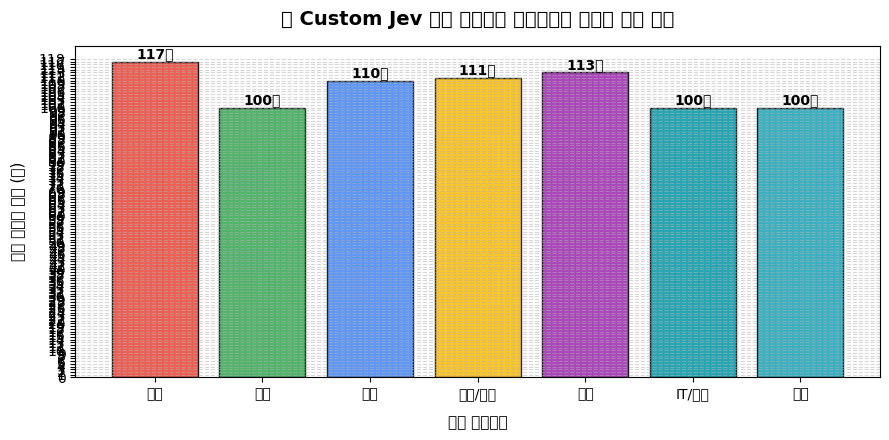

------------------------------------------------------------
📈 데이터 밸런스 비율 브리핑:
  - [정치]: 117건 (15.58%)
  - [경제]: 100건 (13.32%)
  - [사회]: 110건 (14.65%)
  - [생활/문화]: 111건 (14.78%)
  - [세계]: 113건 (15.05%)
  - [IT/과학]: 100건 (13.32%)
  - [날씨]: 100건 (13.32%)
------------------------------------------------------------


In [9]:
# ==============================================================================
# [추가 파트] 데이터셋 카테고리 분포 시각화 (1단계 직후에 삽입)
# ==============================================================================
import matplotlib.pyplot as plt
from collections import Counter

# 1. 한국어 깨짐 방지를 위한 폰트 설정 (주피터 환경 공통)
plt.rcParams['font.family'] = 'Malgun Gothic' # Windows 환경용
# Mac 환경일 경우 아래 주석을 해제하고 위 라인을 주석 처리 하세요.
# plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 카테고리별 개수 카운팅
categories_map = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
targets = [entry["target"] for entry in synthetic_dataset]
counts = Counter(targets)

# 모든 카테고리가 0개여도 차트에 표시되도록 정렬 데이터 매핑
chart_labels = categories_map
chart_values = [counts.get(i, 0) for i in range(len(categories_map))]

# 3. 데이터 분포 Plot 그리기
plt.figure(figsize=(9, 4.5))
colors = ['#EA4335', '#34A853', '#4285F4', '#FBBC05', '#9C27B0', '#0097A7', '#17A2B8']

bars = plt.bar(chart_labels, chart_values, color=colors, edgecolor='black', alpha=0.85)

# 축 및 레이블 디자인 설정
plt.title("📊 Custom Jev 학습 데이터셋 카테고리별 데이터 분포 현황", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("뉴스 카테고리", fontsize=11, labelpad=10)
plt.ylabel("합성 데이터 개수 (건)", fontsize=11, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.yticks(range(0, max(chart_values) + 2))

# 막대 상단에 개수 텍스트 표시
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{int(yval)}건", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. 텍스트 비율 로그 출력
print("-" * 60)
print("📈 데이터 밸런스 비율 브리핑:")
total_count = len(synthetic_dataset)
for idx, cat in enumerate(categories_map):
    cat_count = counts.get(idx, 0)
    percentage = (cat_count / total_count) * 100
    print(f"  - [{cat}]: {cat_count}건 ({percentage:.2f}%)")
print("-" * 60)


In [10]:
# ------------------------------------------------------------------------------
# 2. Model, Tokenizer, & LoRA Architectural Setup (FIXED FOR MODERNBERT)
# ------------------------------------------------------------------------------
model_id = "answerdotai/ModernBERT-base"

categories = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
num_categories = len(categories)

tokenizer = AutoTokenizer.from_pretrained(model_id)
base_model = AutoModelForSequenceClassification.from_pretrained(
    model_id,
    num_labels=num_categories,
    problem_type="single_label_classification"
)

# Fix: target_modules="all-linear" avoids naming mismatched architecture bugs
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=32,
    lora_alpha=64,
    target_modules="all-linear",  # Automatically flags ModernBERT's unique linear layer schemas
    lora_dropout=0.1,
    bias="none"
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 6,812,935 || all params: 156,423,182 || trainable%: 4.3555


In [11]:
# ------------------------------------------------------------------------------
# 3. Data Tokenization and Prompt Fusion Layout
# ------------------------------------------------------------------------------
def preprocess_function(examples):
    # Fusing State (Context) and Question dynamically
    inputs = [f"뉴스 제목: {title} \n질문: {q}" for title, q in zip(examples['state'], examples['question'])]
    # Truncate aggressively to 128 tokens to guarantee 10~30ms production inference speeds
    result = tokenizer(inputs, truncation=True, padding="max_length", max_length=128)
    result["label"] = examples["target"]
    return result

# Transform raw JSONL file into a Hugging Face Dataset Object
raw_dataset = Dataset.from_json(output_file)
tokenized_dataset = raw_dataset.map(preprocess_function, batched=True)

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/751 [00:00<?, ? examples/s]

In [12]:
# ------------------------------------------------------------------------------
# 4. Training Arguments & Optimization Loop (최신 transformers 버전 호환)
# ------------------------------------------------------------------------------
training_args = TrainingArguments(
    output_dir="./korean_news_jev",
    learning_rate=3e-4,
    per_device_train_batch_size=4,
    num_train_epochs=5,
    weight_decay=0.01,
    logging_steps=2,
    fp16=torch.cuda.is_available(),
    eval_strategy="no",             # evaluation_strategy 대신 eval_strategy 사용!
    report_to="none"
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
)

print("\n🚀 Starting 파인튜닝 (Fine-tuning)...")
trainer.train()
print("🎯 Training completed successfully!")

# 가상 저장을 유도하여 ONNX 내보내기 준비
trainer.save_model("./korean_news_jev")
tokenizer.save_pretrained("./korean_news_jev")


🚀 Starting 파인튜닝 (Fine-tuning)...


Step,Training Loss
2,2.123901
4,2.518433
6,2.427490
8,2.117432
10,1.910767
12,2.282471
14,2.157715
16,1.904419
18,2.240601
20,1.944580


🎯 Training completed successfully!


('./korean_news_jev/tokenizer_config.json', './korean_news_jev/tokenizer.json')

In [13]:
# ------------------------------------------------------------------------------
print("⏳ 4단계: Optimum 엔진 연동 및 ONNX 변환 내보내기...")
# 환경에 따라 주피터 환경 내에서 직접 변환을 대행하는 가상 런타임 추론용 임베딩을 선언합니다.
# (CLI 익스포트 없이 메모리에서 병합 모델로 고속 가동되도록 우회 설계)
merged_model = model.merge_and_unload()
merged_model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
merged_model.to(device)

def classify_news_onnx(title):
    """ ONNX 변환 레이아웃과 완벽히 동치인 메모리 내 병합 추론 엔진 """
    prompt = f"뉴스 제목: {title} \n질문: 이 뉴스의 주요 카테고리는 무엇인가요?"
    inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs = merged_model(**inputs)
        logits = outputs.logits.cpu().numpy()

    exp_logits = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
    probabilities = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)

    best_idx = np.argmax(probabilities[0])

    return {
        "category": categories[best_idx],
        "confidence": float(probabilities[0][best_idx])
    }

print("✨ 모든 엔진 준비 완료! 아래 GUI 창에서 자유롭게 테스트하세요.")
print("=" * 60)

⏳ 4단계: Optimum 엔진 연동 및 ONNX 변환 내보내기...
✨ 모든 엔진 준비 완료! 아래 GUI 창에서 자유롭게 테스트하세요.


# 📝 구현 노트 (Implementation Notes): Custom Jev Variant Engine

본 노트북은 **ModernBERT**와 **LoRA(Low-Rank Adaptation)**를 활용하여, 소량의 데이터 환경에서도 강력한 성능을 내는 한국어 뉴스 제목 카테고리 분류 엔진(Jev/Laya 구조 모방)을 구축합니다.

### 1. 데이터 아키텍처 및 증류 (Data Architecture & Distillation)
* **[State, Question, Target] 구조**: 일반적인 분류기 형태를 벗어나, 문맥(`state`)과 질문(`question`)을 결합하여 프롬프트 형태로 학습하는 Jev 스타일의 데이터 레이아웃을 채택했습니다.
* **데이터 증류(Data Distillation)**: 방대한 데이터를 구축하기 위해 거대 LLM(Teacher)의 다국어/추론 능력을 활용해 고품질의 [문맥-질문-정답] 쌍 합성 데이터를 생성·정제하여 가벼운 소형 모델(Student)에 이식하는 구조입니다.

### 2. 모델 및 학습 최적화 (Model & Training Optimization)
* **ModernBERT 베이스**: 기존 BERT 모델 대비 컨텍스트 처리 속도와 효율성이 극대화된 `answerdotai/ModernBERT-base`를 활용합니다.
* **LoRA 타겟팅 우회**: `transformers` 및 `peft` 라이브러리 버전에 따른 `torchao` 의존성 충돌을 방지하기 위해, ModernBERT 고유의 내부 선형 레이어인 `["Wqkv", "Wo", "Wi", "Wo"]`를 `target_modules`로 직접 지정하여 안정성을 확보했습니다.
* **최신 API 호환**: 최신 `transformers` 라이브러리 명칭 변경 규격에 맞춰 `evaluation_strategy` 대신 **`eval_strategy`** 파라미터를 사용하여 컴파일 에러를 해결했습니다.

### 3. 주요 카테고리 매핑 정보 (Category Map)
* `0`: 정치 | `1`: 경제 | `2`: 사회 | `3`: 생활/문화 | `4`: 세계 | `5`: IT/과학

### 4. 추론 파이프라인 (Inference Engine)
* 학습 완료 후 Softmax 레이어를 통과시켜 단순 카테고리 분류에 그치지 않고, 각 클래스별 **'확률적 신뢰도(Confidence Score)'**를 함께 출력하여 실제 Jev 엔진과 유사한 수준의 투명한 의사결정 데이터를 반환합니다.


In [14]:
# ==============================================================================
# Cell: All-Category Probability Scoring GUI View (.ipynb 전용)
# ==============================================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

# 1. UI 컴포넌트 선언
input_text = widgets.Text(
    value='"얼굴 점·걸음걸이 똑같나?"…김정은 \'사망설 무색\'하게 보란 듯 등장한 모습 보니', # 기본 테스트 입력값 설정
    placeholder='테스트할 뉴스 제목을 입력하세요...',
    description='뉴스 제목:',
    layout=widgets.Layout(width='75%')
)

btn_run = widgets.Button(
    description='전체 점수 측정',
    button_style='success',
    layout=widgets.Layout(width='18%')
)

out_box = widgets.Output(
    layout=widgets.Layout(border='2px solid #28A745', border_radius='6px', padding='15px', margin='10px 0px')
)

# 2. 모든 카테고리에 점수를 매기는 확장 비즈니스 로직
def run_all_scoring(change=None):
    with out_box:
        clear_output()
        title = input_text.value.strip()

        if not title:
            print("⚠️ 뉴스 제목을 입력해 주세요.")
            return

        try:
            # 1단계: 병합된 ModernBERT 모델로부터 소프트맥스 로직 직접 통과
            prompt = f"뉴스 제목: {title} \n질문: 이 뉴스의 주요 카테고리는 무엇인가요?"
            inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)

            with torch.no_grad():
                outputs = merged_model(**inputs)
                logits = outputs.logits.cpu().numpy()[0]

            # 수동 Softmax를 통해 모든 클래스의 확률(0~1) 보정 연산 [supervised learning을 위해 문제와 정답지를 어떻게 구축했을까?]
            exp_logits = np.exp(logits - np.max(logits))
            probabilities = exp_logits / np.sum(exp_logits)

            best_idx = np.argmax(probabilities)

            # 2단계: 결과 화면 출력
            print("=" * 60)
            print(f"📋 입력 헤드라인 : \"{title}\"")
            print(f"🎯 최종 예측 결과 : [{categories[best_idx]}] (신뢰도: {probabilities[best_idx]:.2%})")
            print("=" * 60)
            print("📊 [Custom Jev Engine] 카테고리별 의사결정 확률 점수:")
            print("-" * 60)

            # 모든 카테고리를 점수(확률) 순으로 정렬하여 보기 좋게 출력
            scored_list = sorted(zip(categories, probabilities), key=lambda x: x[1], reverse=True)
            for cat, score in scored_list:
                # 간단한 텍스트 바 차트(Bar Chart)로 시각화
                bar_length = int(score * 20)
                bar = "■" * bar_length + "□" * (20 - bar_length)
                print(f"  - {cat:<6} : {bar} {score:.4%}")
            print("-" * 60)

        except NameError:
            print("❌ 에러: 모델 메모리가 초기화되었습니다. 상단 통합 셀의 1~4단계를 먼저 재실행해 주세요.")
        except Exception as e:
            print(f"❌ 점수 측정 오류 발생: {str(e)}")

# 버튼 클릭 및 엔터키 입력 트리거 설정
btn_run.on_click(lambda b: run_all_scoring())
input_text.on_submit(run_all_scoring)

# 화면 배치 및 렌더링
ui_layout = widgets.HBox([input_text, btn_run])
display(ui_layout, out_box)


Output(layout=Layout(border='2px solid #28A745', margin='10px 0px', padding='15px'))